In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

processed_dir = Path.cwd() / "processed_data"

X_train = pd.read_csv(processed_dir / "rocket_league_X_train.csv")
X_test = pd.read_csv(processed_dir / "rocket_league_X_test.csv")
y_train = pd.read_csv(processed_dir / "rocket_league_y_train.csv")
y_test = pd.read_csv(processed_dir / "rocket_league_y_test.csv")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

display(X_train.head())
display(y_train.head())

Training features: (5513, 7)
Testing features: (1379, 7)
Training labels: (5513, 11)
Testing labels: (1379, 11)


,BallAcceleration,Time,DistanceWall,DistanceCeil,DistanceBall,PlayerSpeed,BallSpeed
0,0.078149,0.787573,0.012814,0.498484,-0.464514,1.510362,1.714748
1,-0.010577,0.302208,-0.232953,-1.336718,-0.436809,-0.947428,-0.464584
2,0.051207,-0.942074,-0.258273,-1.029397,-0.452665,-0.863758,0.102511
3,0.042367,-0.540818,-0.267634,-0.354635,-0.558636,-0.666746,0.319574
4,0.036909,0.161574,-0.041596,0.535575,-0.389867,0.567175,0.945926


,up,accelerate,slow,goal,left,boost,camera,down,right,slide,jump
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier

# Create the base classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Wrap it for multi-label prediction
model = MultiOutputClassifier(rf_model)

# Train the model
model.fit(X_train, y_train)

print("Multi-output Random Forest model trained successfully!")

Multi-output Random Forest model trained successfully!


In [5]:
# Predict action labels for test data
y_pred = model.predict(X_test)

# Convert predictions into a DataFrame
y_pred_df = pd.DataFrame(y_pred, columns=y_test.columns)

print("Predictions completed!")
print("Prediction shape:", y_pred_df.shape)

display(y_pred_df.head())

Predictions completed!
Prediction shape: (1379, 11)


,up,accelerate,slow,goal,left,boost,camera,down,right,slide,jump
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [6]:
from sklearn.metrics import accuracy_score, hamming_loss, classification_report

# Overall subset accuracy:
# All predicted labels for a row must match the true labels
subset_acc = accuracy_score(y_test, y_pred)

# Fraction of individual labels predicted incorrectly
h_loss = hamming_loss(y_test, y_pred)

print("Subset Accuracy:", round(subset_acc, 4))
print("Hamming Loss:", round(h_loss, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=y_test.columns,
        zero_division=0
    )
)

Subset Accuracy: 0.1581
Hamming Loss: 0.1274

Classification Report:
              precision    recall  f1-score   support

          up       0.72      0.32      0.44        56
  accelerate       0.72      0.47      0.57       449
        slow       1.00      1.00      1.00        39
        goal       0.69      0.18      0.28       173
        left       0.00      0.00      0.00        30
       boost       0.60      0.14      0.22       361
      camera       0.33      0.06      0.10       195
        down       1.00      0.33      0.50        12
       right       0.93      0.99      0.96      1271
       slide       0.56      0.17      0.26       356
        jump       0.72      0.58      0.64       571

   micro avg       0.82      0.57      0.68      3513
   macro avg       0.66      0.38      0.45      3513
weighted avg       0.74      0.57      0.61      3513
 samples avg       0.84      0.60      0.66      3513



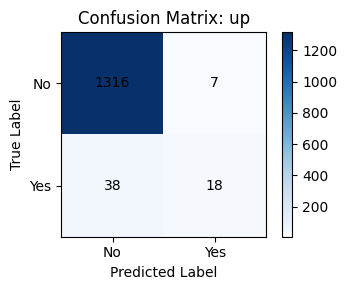

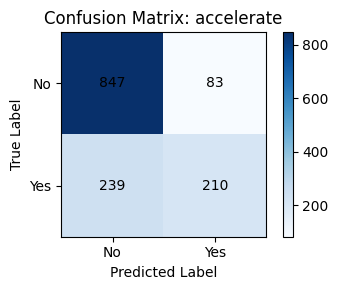

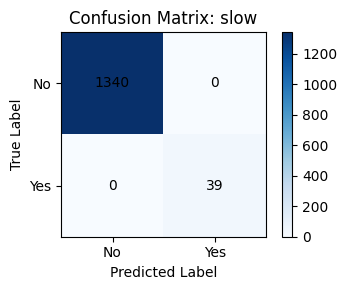

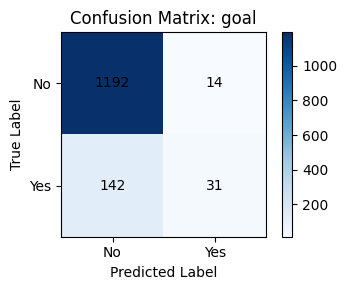

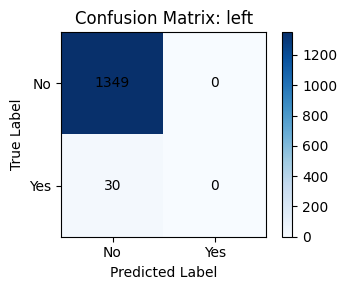

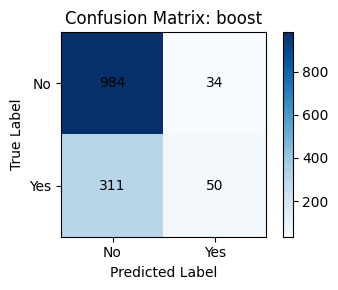

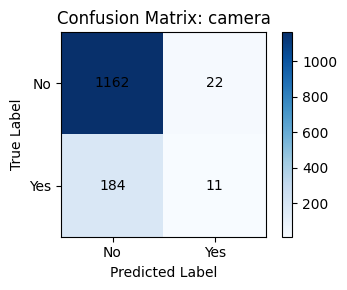

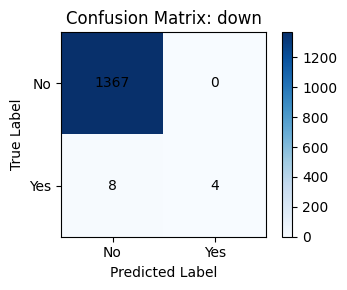

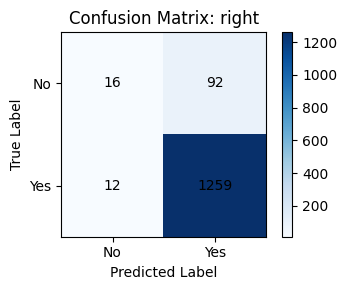

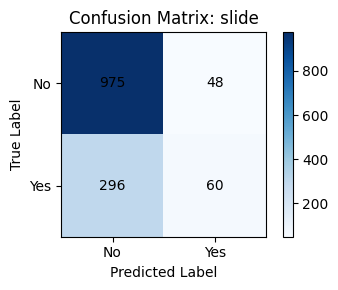

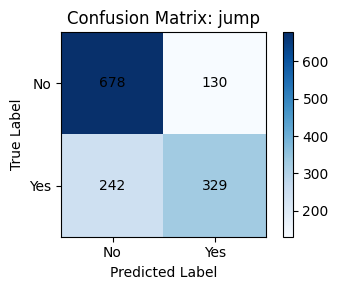

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix

# Calculate confusion matrices for each action label
conf_matrices = multilabel_confusion_matrix(y_test, y_pred)

# Plot one confusion matrix per action
for i, action in enumerate(y_test.columns):
    cm = conf_matrices[i]

    plt.figure(figsize=(4, 3))
    plt.imshow(cm, interpolation="nearest", cmap="Blues")
    plt.title(f"Confusion Matrix: {action}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks([0, 1], ["No", "Yes"])
    plt.yticks([0, 1], ["No", "Yes"])

    for row in range(2):
        for col in range(2):
            plt.text(col, row, cm[row, col], ha="center", va="center")

    plt.colorbar()
    plt.tight_layout()
    plt.show()

In [8]:
from pathlib import Path
import joblib

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

# Save trained model
joblib.dump(model, output_dir / "rocket_league_random_forest_model.pkl")

# Save predictions alongside actual labels
prediction_results = y_test.reset_index(drop=True).add_prefix("Actual_")
predicted_results = y_pred_df.reset_index(drop=True).add_prefix("Predicted_")

results_df = pd.concat([prediction_results, predicted_results], axis=1)
results_df.to_csv(
    output_dir / "rocket_league_classification_predictions.csv",
    index=False
)

print("Model and prediction results saved successfully.")

Model and prediction results saved successfully.


## Result

The Rocket League Skillshots dataset was used to train a multi-output Random Forest classification model. The model predicted multiple gameplay action labels from the input measurements. Performance was evaluated using subset accuracy, Hamming loss, classification report, and confusion matrices for each action label.

The trained model and prediction results were saved for future use.

## Conclusion

The multi-label classification experiment was completed successfully. The Random Forest model learned relationships between gameplay measurements and action indicators. Evaluation metrics were used to assess its prediction performance across the action labels.